# 07 — Market regimes, HMM features, neural networks and blends

This notebook completes Alisa's daily-model research after the CatBoost/XGBoost comparison. It covers the market-regime motivation, hidden Markov models, tabular and sequence networks, and the fixed LightGBM–network blend.

The complete four-year tables display Alisa's saved studies, with arithmetic and adoption decisions checked below. Fresh worked examples rebuild the regime inputs, fit a historical HMM, check forward filtering, refit the five HMM tree specifications for 2022, and train all three neural architectures for the 2022 fold. Fresh training verification covers 2022. The complete four-year comparison tables come from the saved studies, with numerical differences shown alongside the worked examples.

The original studies retained tuned LightGBM. Regime features worsened aggregate development accuracy. Individual networks trailed the champion, while the fixed blend's small development improvement fell below the adoption threshold. The fresh examples are evaluated separately from the saved conclusions.

This is an extension of Checkpoint 4. Checkpoint 5 will begin with notebook 08 on splines, tail mixtures, Tweedie loss and rebalance features, after review. Later daily summary, intraday and sequential-update notebooks become 09, 10 and 11 respectively.

In [1]:
from pathlib import Path
import sys
import tempfile
import json
import hashlib
import importlib.metadata
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown, Image

PROJECT_ROOT = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
                    if (p / "blackrock_data").is_dir())
sys.path.insert(0, str(PROJECT_ROOT))
DATA = PROJECT_ROOT / "blackrock_data"
RESULTS = PROJECT_ROOT / "outputs"
work = tempfile.TemporaryDirectory(prefix="auction-master-")
con = duckdb.connect()
con.execute("SET threads=4")
con.execute("SET memory_limit='2GB'")
con.execute("SET temp_directory=?", [work.name])
AUCTION = str(DATA / "stock_daily/auction_daily/year=*/auction_daily_*.parquet")
CRSP = str(DATA / "stock_daily/crsp_daily/year=*/crsp_daily_*.parquet")
TRADE = str(DATA / "stock_intraday/trade_checkpoints/year=*/trade_checkpoints_*.parquet")
MARKET = str(DATA / "market/market_daily.parquet")
SECTOR = str(DATA / "sector/sector_daily.parquet")
EVENTS = str(DATA / "events/event_calendar.parquet")
INDUSTRY = str(DATA / "reference/industry_history.parquet")
ANOMALIES = str(DATA / "quality/auction_source_anomalies.parquet")
def sql(query, params=None):
    return con.execute(query, params or []).df()
def saved(relative):
    return pd.read_csv(RESULTS / relative)
pd.set_option("display.max_columns", 16)
pd.set_option("display.max_rows", 35)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook", palette="colorblind")
plt.rcParams.update({"figure.figsize": (11, 4.5), "figure.dpi": 110})
display(pd.DataFrame({"package": ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"],
                      "version": [importlib.metadata.version(p) for p in ["duckdb", "numpy", "pandas", "matplotlib", "seaborn"]]}))
import os
import time
import pickle
import logging
from datetime import datetime, timezone
import gc
import lightgbm as lgb
import torch
import hmmlearn
from notebooks.modeling_utils import fit_preprocessor, apply_preprocessor, forecast_metrics
sys.path.insert(0, str(PROJECT_ROOT / 'notebooks'))
warnings.filterwarnings('ignore', message='X does not have valid feature names')
logging.getLogger('hmmlearn').setLevel(logging.ERROR)
RUN = RESULTS / 'experiments/29_regimes_neural_master_audit'
for directory in [RUN, RUN / 'models', RUN / 'predictions', RUN / 'samples', RUN / 'history']:
    directory.mkdir(parents=True, exist_ok=True)
C = RESULTS / 'eda/16c_regime_motivation'
H = RESULTS / 'eda/16d_hmm_regime_features'
N = RESULTS / 'eda/16e_sequence_neural_networks'
A = RESULTS / 'eda/16a_lightgbm_improvements'
DEV = [2022, 2023, 2024]
TUNED = 'lgbm_61_ratios_large_tuned'
HCONTROL = 'lgbm_control'
FROZEN = json.loads((RESULTS / 'eda/09_global_finalists/frozen_global_benchmark.json').read_text())['champion']

def read(folder, name):return pd.read_csv(folder / name)
def progress(message):
    line = f'{datetime.now(timezone.utc).isoformat()} {message}'
    print(line, flush=True)
    with (RUN / 'progress.log').open('a') as handle:handle.write(line + '\n')
def write_json(path, value):
    temporary = path.with_suffix(path.suffix + '.partial')
    temporary.write_text(json.dumps(value, indent=2))
    temporary.replace(path)
def file_hash(path):
    h = hashlib.sha256()
    with Path(path).open('rb') as handle:
        for chunk in iter(lambda: handle.read(8*1024*1024), b''):h.update(chunk)
    return h.hexdigest()
def write_frame(frame, path):
    temporary = path.with_suffix('.partial')
    temporary.unlink(missing_ok=True)
    con.register('audit_output', frame)
    try:con.execute('COPY audit_output TO ? (FORMAT PARQUET, COMPRESSION ZSTD)', [str(temporary)])
    finally:con.unregister('audit_output')
    temporary.replace(path)

paths = [RESULTS / 'eda/05_feature_engineering/enriched_daily_panel.parquet',
         PROJECT_ROOT / 'midterm presentation/data_analysis/cache/enriched_daily_panel.parquet',
         RESULTS / 'experiments/21_ridge_target_definitions/daily_panel.parquet']
PANEL = next(path for path in paths if path.is_file())
os.environ['AUCTION_DAILY_PANEL'] = str(PANEL)
import challenger_utils as cu
import regime_utils as ru
import sequence_utils as su
assert not cu.SMOKE
cu.con.execute('SET threads=1')
torch.set_num_threads(2)
versions = {name: importlib.metadata.version(name) for name in ['lightgbm', 'torch', 'hmmlearn', 'duckdb', 'numpy', 'pandas', 'scikit-learn']}
display(pd.Series(versions, name='execution version').to_frame())
print('Neural training device:', su.DEVICE)

,package,version
0,duckdb,1.5.6
1,numpy,2.4.6
2,pandas,3.1.1
3,matplotlib,3.11.2
4,seaborn,0.13.2


,execution version
lightgbm,4.6.0
torch,2.15.0
hmmlearn,0.3.3
duckdb,1.5.6
numpy,2.4.6
pandas,3.1.1
scikit-learn,1.9.1


Neural training device: mps


## Why look for market regimes?

Alisa examined six slow-moving market measures. They describe market conditions rather than a stock's absolute price level. Each predictor is computed at the prior close and shifted to its forecast date. Calendar event days are excluded from the slow activity and auction-share baselines.

| Input | Construction and rationale |
| --- | --- |
| Activity | Market volume relative to its previous 60 regular-day median, smoothed over five regular days |
| Realised volatility | Log annualised 20-day market-return volatility |
| Auction-share deviation | Log 20-regular-day auction share relative to its prior one-year median |
| Dispersion | Log 20-day average return dispersion |
| Fear premium | Log median implied volatility minus log realised volatility |
| Drawdown | Market index relative to its trailing one-year high |

These variables are persistent. A useful forecast correction also needs predictable changes in the daily model's errors or its feature relationships. Persistence in the market inputs alone does not establish that opportunity.

2026-11-18T06:11:51.471471+00:00 Rebuilding historical market-regime inputs from source aggregates


,activity,realized_vol,auction_share_dev,dispersion,fear_premium,drawdown,model_daily_mean_error
lag_days,,,,,,,
1,0.9653,0.9887,0.9908,0.9951,0.9788,0.9693,0.0242
2,0.8959,0.9747,0.9768,0.9869,0.9551,0.9436,0.0439
5,0.6040,0.9186,0.9146,0.9480,0.8637,0.8637,-0.0014
10,0.3496,0.8029,0.7476,0.8517,0.6851,0.7483,0.0053
20,0.1677,0.5526,0.3153,0.6564,0.3391,0.5247,-0.0046
40,-0.0797,0.3764,0.1257,0.5376,0.2270,0.2493,0.0192
60,-0.0211,0.1966,0.5752,0.5224,0.0765,0.0931,0.0292


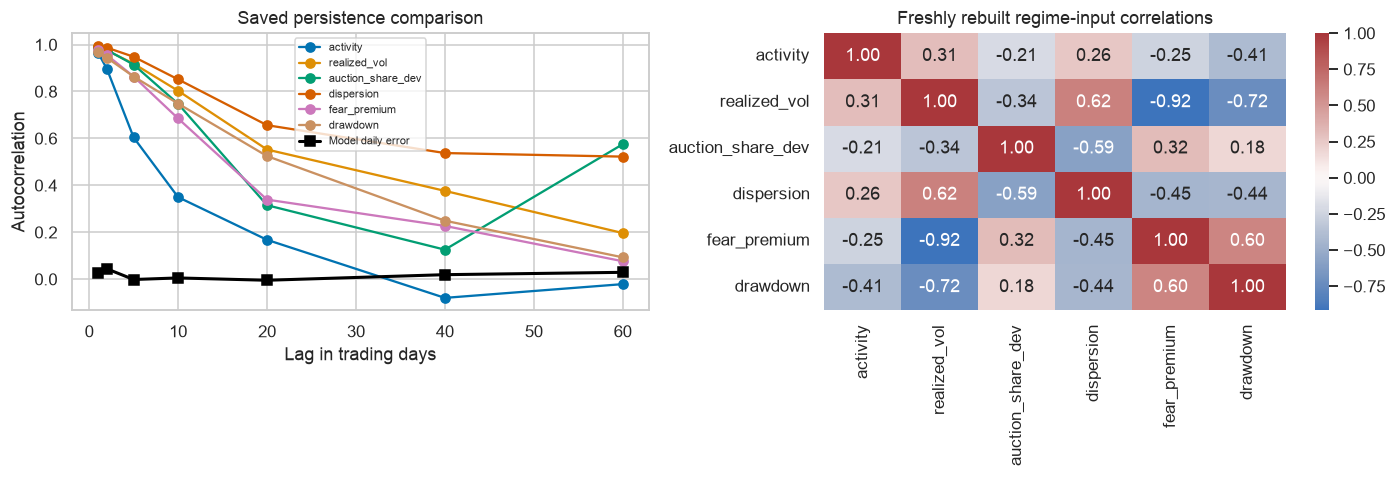

,low,mid,high
input,,,
activity,0.2473,0.3390,0.4138
realized_vol,0.1336,0.5015,0.3649
auction_share_dev,0.2762,0.3649,0.3589
dispersion,0.0000,0.1635,0.8365
fear_premium,0.2894,0.3917,0.3188
drawdown,0.4148,0.3380,0.2473


In [2]:
progress('Rebuilding historical market-regime inputs from source aggregates')
inputs = ru.build_regime_inputs(cu.con, PROJECT_ROOT)
write_frame(inputs.reset_index(), RUN / 'regime_inputs.parquet')
autocorrelation = read(C, 'q1_autocorrelation.csv').set_index('lag_days')
display(autocorrelation)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for column in ru.INPUTS:
    axes[0].plot(autocorrelation.index, autocorrelation[column], marker='o', label=column)
axes[0].plot(autocorrelation.index, autocorrelation.model_daily_mean_error, color='black', linewidth=2, marker='s', label='Model daily error')
axes[0].set(title='Saved persistence comparison', xlabel='Lag in trading days', ylabel='Autocorrelation')
axes[0].legend(fontsize=7)
correlation = inputs.loc['2015-01-01':, ru.INPUTS].corr()
sns.heatmap(correlation, annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[1])
axes[1].set(title='Freshly rebuilt regime-input correlations')
plt.tight_layout(); plt.show()
display(read(C, 'q6_tercile_shares_2022_2025.csv').rename(columns={'Unnamed: 0': 'input'}).set_index('input'))

The saved model's mean daily error had lag-one correlation around **0.024**, while the input correlations were near 0.97–1.00. Fear premium was strongly redundant with realised volatility. Dispersion drifted upward, with no 2022–2025 observations in its original low tercile. The HMM therefore retained activity, realised volatility, auction-share deviation and drawdown.

Alisa also examined Gaussian-mixture BIC, response slopes by tercile, quarterly changes in slopes, and the most that a hindsight correction could remove from each regime's bias. The Gaussian mixture was a descriptive 2015–2025 analysis. Predictive HMMs were fitted separately within historical training windows.

,components,bic,log_likelihood,bic_change_vs_previous
0,1,"21,724.3487","-10,826.7603",NaN
1,2,"21,099.7595","-10,475.1168",-624.5892
2,3,"20,892.3774","-10,332.0768",-207.3821
3,4,"20,946.6878","-10,319.8831",54.3105
4,5,"20,886.3025","-10,250.3415",-60.3853
5,6,"20,897.0730","-10,216.3779",10.7705


,input,tercile,stock_days,mean_r,sd_r,slope_on_spike_ratio,slope_on_abnormal_volume
0,activity,low,946488,-0.0256,0.5969,0.2076,0.2531
1,activity,mid,1043000,0.0420,0.6077,0.2057,0.2528
2,activity,high,1132462,0.0535,0.5608,0.1974,0.2543
3,auction_share_dev,low,910424,0.0375,0.5607,0.2118,0.2469
4,auction_share_dev,mid,1024637,0.0500,0.5721,0.2126,0.2572
5,auction_share_dev,high,1007929,-0.0076,0.6114,0.2036,0.2671
6,dispersion,low,673473,0.0297,0.6780,0.1769,0.2544
7,dispersion,mid,848741,0.0220,0.6059,0.1986,0.2592
8,dispersion,high,1599736,0.0260,0.5368,0.2282,0.2583
9,drawdown,low,1141432,0.0358,0.5777,0.2107,0.2624


,quarterly change of input,slope_on_spike_ratio,slope_on_abnormal_volume,mean_r,sd_r
0,activity,-0.0299,0.0492,0.3337,-0.1666
1,realized_vol,-0.2457,-0.1361,0.0912,0.0133
2,auction_share_dev,0.1787,0.2108,-0.0758,-0.1371
3,dispersion,-0.2433,-0.1640,0.1342,-0.1134
4,fear_premium,0.2315,0.0944,-0.0416,-0.0808
5,drawdown,0.2394,0.0581,0.0245,0.0399


,grouping,groups,stock_days,rmse_before,rmse_after_oracle,max_gain
0,activity_tercile,3,1271378,0.4554,0.4551,0.0003
1,realized_vol_tercile,3,1271378,0.4554,0.4550,0.0004
2,auction_share_dev_tercile,3,1271378,0.4554,0.4549,0.0005
3,dispersion_tercile,2,1271378,0.4554,0.4551,0.0003
4,fear_premium_tercile,3,1168150,0.4575,0.4570,0.0005
5,drawdown_tercile,3,1271378,0.4554,0.4550,0.0004
6,core_combination,27,1271378,0.4554,0.4543,0.0011
7,perfect daily market shift (not achievable),1003,1271378,0.4554,0.4340,0.0214


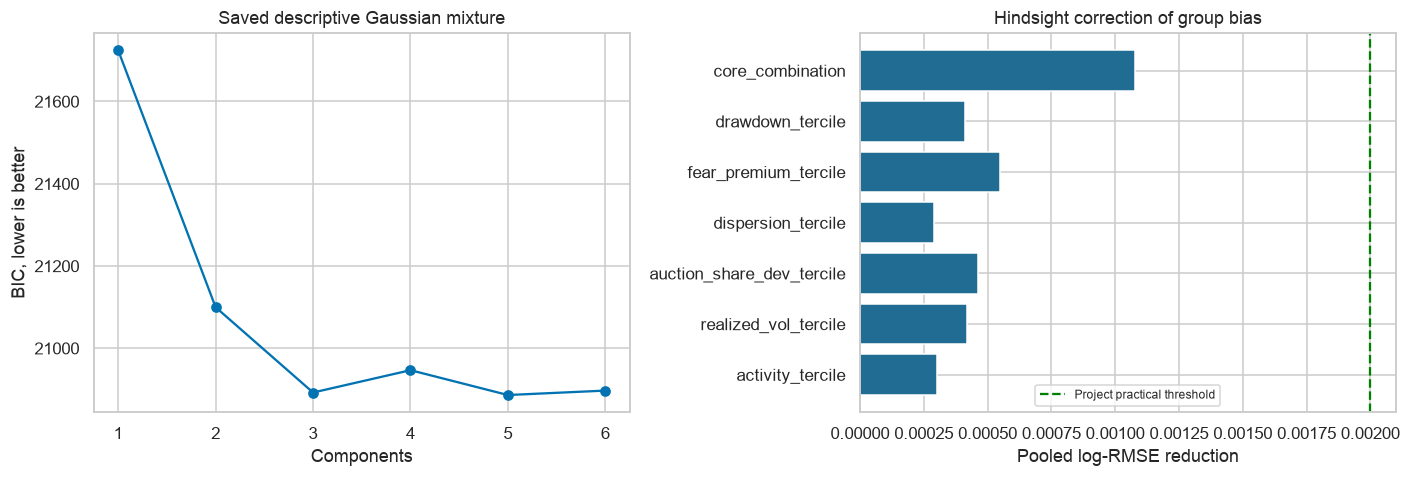

In [3]:
evidence = json.loads((C / 'evidence_summary.json').read_text())
mixture = read(C, 'q2_gaussian_mixture_bic.csv')
oracle = read(C, 'q5_oracle_gain_upper_bound.csv')
display(mixture)
display(read(C, 'q3_target_by_regime.csv'))
display(read(C, 'q4_relationship_vs_inputs_spearman_changes.csv'))
display(oracle)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(mixture.components, mixture.bic, marker='o')
axes[0].set(title='Saved descriptive Gaussian mixture', xlabel='Components', ylabel='BIC, lower is better')
part = oracle[~oracle.grouping.str.startswith('perfect daily')]
axes[1].barh(part.grouping, part.max_gain, color='#216c93')
axes[1].axvline(.002, color='green', linestyle='--', label='Project practical threshold')
axes[1].set(title='Hindsight correction of group bias', xlabel='Pooled log-RMSE reduction')
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

The combined regime-bias correction gained about **0.00108** log RMSE with hindsight. This is an upper bound for that group-bias correction, under the recorded grouping and period. It does not bound every possible nonlinear use of regimes. The table pools 2022–2025 and differs from the equal-year development metric used for model selection.

These diagnostics supplied a weak case for improving the point forecast. Regimes may still describe differences in uncertainty, but prediction intervals were outside this point-accuracy study.

## Hidden Markov model design

A Gaussian HMM represents a persistent hidden state with a transition matrix and a Gaussian distribution of the four observed inputs in each state. Alisa fitted full-covariance models with ten random restarts per state count. Historical BIC selected among 1–6 states, and a fixed three-state version supplied a sensitivity check.

Inputs are standardised inside each fit. State labels are ordered by their fitted realised-volatility mean. The nine predictors are calm/stress probabilities, state rank, entropy, regime age and four expected standardised inputs. **Forward filtering** uses observations available so far. The library's smoothed state probabilities would incorporate subsequent observations and were excluded from this forecasting design.

All five tree candidates use the same 61 daily sources and large sample tier. The HMM control is the **untuned large-tier LightGBM**. The neural comparison uses the tuned champion.

In [4]:
hmm_metrics = read(H, 'candidate_metrics.csv')
neural_metrics = read(N, 'candidate_metrics.csv')
a_metrics = read(A, 'candidate_metrics.csv')
annual_hmm = hmm_metrics.pivot(index='candidate', columns='test_year', values='rmse_log')
annual_neural = neural_metrics.pivot(index='candidate', columns='test_year', values='rmse_log')
source_check_rows = []
for folder, metrics in [(H, hmm_metrics), (N, neural_metrics)]:
    annual = metrics.pivot(index='candidate', columns='test_year', values='rmse_log')
    for row in read(folder, 'candidate_selection.csv').itertuples():
        np.testing.assert_allclose(row.development_rmse_log, annual.loc[row.candidate, DEV].mean(), atol=1e-12)
        np.testing.assert_allclose(row.confirmation_rmse_log, annual.loc[row.candidate, 2025], atol=1e-12)
        if row.candidate != row.reference:
            difference = annual.loc[row.candidate, DEV] - annual.loc[row.reference, DEV]
            np.testing.assert_allclose(row.rmse_change_vs_reference, difference.mean(), atol=1e-12)
            expected = bool(difference.mean() <= -.002 and difference.max() <= .002 and row.log_mae_ci_97_5 < 0)
            assert bool(row.passes_gate) == expected
        source_check_rows.append({'study': folder.name, 'candidate': row.candidate, 'reference': row.reference, 'verified': True})
control_16a = a_metrics[a_metrics.candidate.eq('lgbm_61_ratios_large')].set_index('test_year').rmse_log
np.testing.assert_allclose(annual_hmm.loc[HCONTROL], control_16a.reindex(annual_hmm.columns), atol=1e-12)
bic = read(H, 'hmm_bic_by_fold.csv')
for _, group in bic.groupby(['test_year', 'phase']):
    assert group.loc[group.bic.idxmin(), 'chosen']
    np.testing.assert_array_equal(group.parameters, [ru.hmm_parameter_count(int(k), 4) for k in group.states])
    implied_log_n = (group.bic + 2*group.log_likelihood) / group.parameters
    np.testing.assert_allclose(implied_log_n, np.repeat(implied_log_n.iloc[0], len(group)), atol=1e-10)
display(bic[bic.chosen][['test_year', 'phase', 'states', 'window']].set_index(['test_year', 'phase']))
summary_hmm = hmm_metrics[hmm_metrics.test_year.isin(DEV)].groupby('candidate').agg(
    development_log_RMSE=('rmse_log','mean'), WAPE=('wape','mean'), bias=('aggregate_bias','mean'))
summary_hmm['2025_log_RMSE'] = annual_hmm[2025]
summary_hmm['change_vs_control'] = summary_hmm.development_log_RMSE - summary_hmm.loc[HCONTROL,'development_log_RMSE']
display(summary_hmm)

states     window
test_year phase                   
2022      tune        6  2016–2020
          refit       6  2017–2021
2023      tune        6  2017–2021
          refit       6  2018–2022
2024      tune        6  2018–2022
          refit       6  2019–2023
2025      tune        6  2019–2023
          refit       6  2020–2024

,development_log_RMSE,WAPE,bias,2025_log_RMSE,change_vs_control
candidate,,,,,
lgbm_control,0.4654,0.3507,-0.1470,0.4236,0.0000
lgbm_plus_hmm_bic,0.4721,0.3546,-0.1495,0.4333,0.0067
lgbm_plus_hmm_k3,0.4672,0.3524,-0.1506,0.4367,0.0018
lgbm_plus_inputs_and_hmm_bic,0.4730,0.3563,-0.1490,0.4342,0.0076
lgbm_plus_regime_inputs,0.4695,0.3539,-0.1522,0.4359,0.0041
rolling5_residual_auction_calendar_liquidity,0.4879,0.3674,-0.1448,0.4467,0.0225


BIC selected six states, the upper search limit, in every saved tuning and refit window. The fixed three-state HMM was the least harmful regime addition, but every addition worsened mean development accuracy and 2025 accuracy versus the matching control. High persistence, changing state profiles and attractive training split gains did not translate into a better out-of-time point forecast.

The source tree study tested a control, four raw regime inputs, BIC HMM features, three-state HMM features, and raw inputs plus BIC HMM features. Its leaf search tested 15, 31 and 63 leaves. The following worked refits reuse the saved historical 2022 tree choices and learn the HMM on 2017–2021, the appropriate final-refit window.

,states,log_likelihood,parameters,bic,chosen
0,1,"-6,205.8414",14,"12,511.6159",False
1,2,"-4,669.3855",31,"9,560.0512",False
2,3,"-4,124.1713",50,"8,605.2463",False
3,4,"-3,737.4849",71,"7,981.7729",False
4,5,"-3,403.8718",94,"7,478.7225",False
5,6,"-3,113.2902",119,"7,076.0111",True


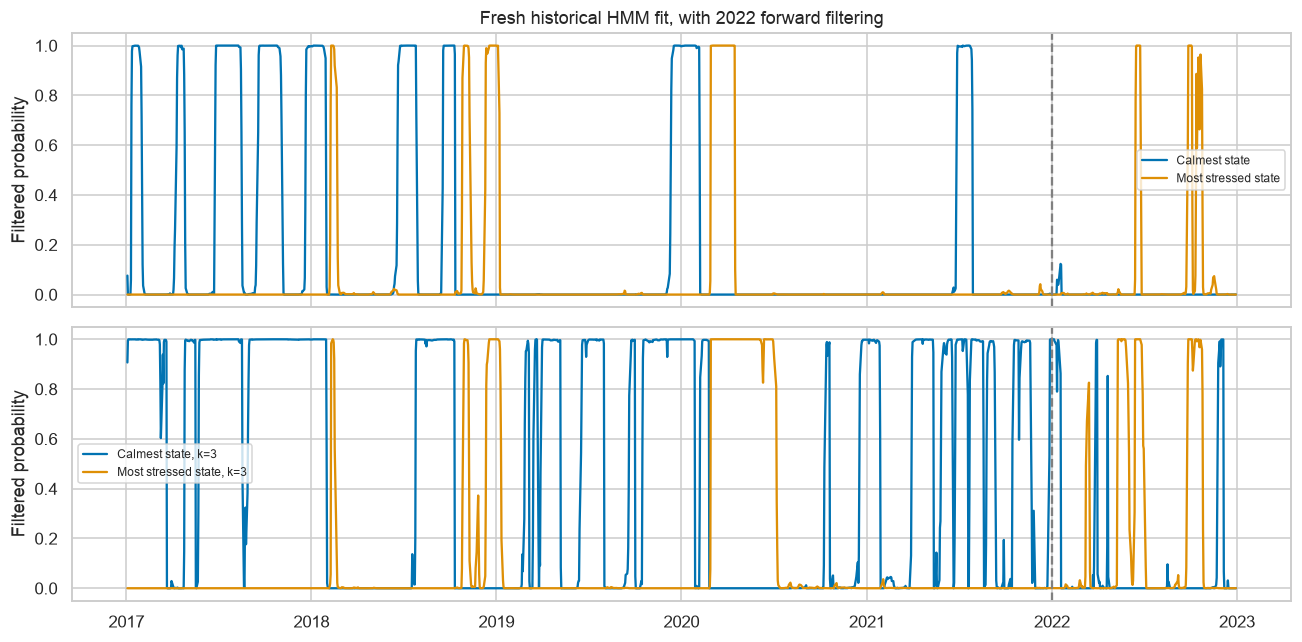

2026-11-18T06:11:52.709278+00:00 HMM forward-filter truncation and probability checks passed


In [5]:
HMM_CANDIDATES = [HCONTROL, 'lgbm_plus_regime_inputs', 'lgbm_plus_hmm_bic',
                  'lgbm_plus_hmm_k3', 'lgbm_plus_inputs_and_hmm_bic']
NN_CANDIDATES = [('nn_mlp_tabular', 'tabular'), ('nn_cnn_lstm_sequence', 'sequence'), ('nn_cnn_lstm_hybrid', 'hybrid')]
plan = {'version': 1, 'year': 2022, 'panel_hash': file_hash(PANEL), 'versions': versions,
        'device': str(su.DEVICE), 'features': cu.RATIO_SET, 'hmm_inputs': ru.HMM_INPUTS,
        'hmm_states': list(range(1,7)), 'hmm_restarts': 10, 'hmm_window': ['2017-01-01','2021-12-31'],
        'neural_training': su.TRAIN, 'sequence_days': su.SEQ_LEN, 'sequence_channels': su.CHANNELS,
        'sequence_normalisation_fallback': 'fit only on corresponding historical fitting frame',
        'row_caps': cu.TIERS['large'], 'seed': cu.SEED}
PLAN_HASH = hashlib.sha256(json.dumps(plan, sort_keys=True).encode()).hexdigest()
if (RUN / 'plan.json').is_file():assert json.loads((RUN / 'plan.json').read_text()) == plan
else:write_json(RUN / 'plan.json', plan)

hmm_path = RUN / 'hmm_features_2022.parquet'
if hmm_path.is_file() and (RUN / 'hmm_models.pkl').is_file():
    extra = sql(f"SELECT * FROM read_parquet('{hmm_path}') ORDER BY date").set_index('date')
    with (RUN / 'hmm_models.pkl').open('rb') as handle:hmm_saved = pickle.load(handle)
    assert hmm_saved['plan_hash'] == PLAN_HASH
    bic_model, scaler = hmm_saved['bic_model'], hmm_saved['bic_scaler']
    fresh_bic = read(RUN, 'fresh_hmm_bic.csv')
else:
    progress('Fitting fresh 2022 refit-window HMMs with ten random restarts')
    bic_features, fresh_bic, bic_profile, bic_model, scaler = ru.hmm_regime_features(inputs, '2017-01-01', '2021-12-31', restarts=10, seed=2022)
    three_features, _, three_profile, three_model, three_scaler = ru.hmm_regime_features(inputs, '2017-01-01', '2021-12-31', restarts=10, seed=2022, states=3)
    extra = pd.concat([inputs[ru.HMM_INPUTS].add_prefix('regime_'), bic_features,
                      three_features.rename(columns=lambda name:name.replace('hmm_','hmm3_'))], axis=1)
    write_frame(extra.reset_index(), hmm_path)
    fresh_bic.to_csv(RUN / 'fresh_hmm_bic.csv', index=False)
    pd.concat([bic_profile.assign(model='BIC'), three_profile.assign(model='three states')]).to_csv(RUN / 'fresh_hmm_profiles.csv')
    with (RUN / 'hmm_models.pkl').open('wb') as handle:
        pickle.dump({'plan_hash':PLAN_HASH, 'bic_model':bic_model, 'bic_scaler':scaler,
                     'three_model':three_model, 'three_scaler':three_scaler}, handle)
mean, scale = scaler
observations = ((inputs[ru.HMM_INPUTS] - mean) / scale)
cutoff = pd.Timestamp('2022-06-30')
full_probs = ru.filter_hmm(bic_model, observations.to_numpy())
truncated_probs = ru.filter_hmm(bic_model, observations.loc[:cutoff].to_numpy())
np.testing.assert_allclose(full_probs[:len(truncated_probs)], truncated_probs, atol=1e-12, rtol=1e-12)
np.testing.assert_allclose(full_probs.sum(axis=1), 1, atol=1e-12)
assert inputs.loc['2017-01-01':'2021-12-31',ru.HMM_INPUTS].dropna().index.max() < pd.Timestamp('2022-01-01')
display(fresh_bic)
fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
part = extra.loc['2017-01-01':'2022-12-31']
axes[0].plot(part.index, part.hmm_p_calm, label='Calmest state')
axes[0].plot(part.index, part.hmm_p_stress, label='Most stressed state')
axes[1].plot(part.index, part.hmm3_p_calm, label='Calmest state, k=3')
axes[1].plot(part.index, part.hmm3_p_stress, label='Most stressed state, k=3')
for ax in axes:
    ax.axvline(pd.Timestamp('2022-01-01'), color='grey', linestyle='--')
    ax.legend(fontsize=8); ax.set(ylabel='Filtered probability')
axes[0].set_title('Fresh historical HMM fit, with 2022 forward filtering')
plt.tight_layout();plt.show()
progress('HMM forward-filter truncation and probability checks passed')

In [6]:
hmm_output_path = RUN / 'predictions/hmm_worked_2022.parquet'
if hmm_output_path.is_file() and (RUN / 'hmm_worked_metrics.csv').is_file():
    hmm_worked = read(RUN, 'hmm_worked_metrics.csv')
    progress('Reusing completed fresh 2022 HMM tree refits')
else:
    refit = cu.load_period(2017,2022,1000000,cu.SEED+200+2022)
    test = cu.load_period(2022,2023)
    refit = cu.attach_extra(refit, extra)
    test = cu.attach_extra(test, extra)
    raw_features = [f'regime_{name}' for name in ru.HMM_INPUTS]
    three_features = [name.replace('hmm_','hmm3_') for name in ru.HMM_FEATURES]
    all_extra = raw_features + ru.HMM_FEATURES + three_features
    continuous = cu.CONTINUOUS + all_extra
    xr, prep = fit_preprocessor(refit, continuous, cu.BOOLEAN, cu.CATEGORICAL)
    xe = apply_preprocessor(test, prep, continuous, cu.BOOLEAN, cu.CATEGORICAL)
    target, base = cu.residual_target_and_base(refit,test)
    allowed = {HCONTROL:cu.RATIO_SET, 'lgbm_plus_regime_inputs':cu.RATIO_SET+raw_features,
               'lgbm_plus_hmm_bic':cu.RATIO_SET+ru.HMM_FEATURES,
               'lgbm_plus_hmm_k3':cu.RATIO_SET+three_features,
               'lgbm_plus_inputs_and_hmm_bic':cu.RATIO_SET+raw_features+ru.HMM_FEATURES}
    trials = read(H,'hyperparameter_validation.csv').query('test_year == 2022')
    choices = trials.loc[trials.groupby('candidate').validation_rmse_log.idxmin()].set_index('candidate')
    output = test[['date','permno','auction_volume']].copy()
    rows=[]
    for name in HMM_CANDIDATES:
        choice=choices.loc[name];mask=cu.feature_mask(prep,allowed[name])
        progress(f'Fresh 2022 HMM specification {name}: refitting {int(choice.best_iteration)} trees')
        model=lgb.LGBMRegressor(n_estimators=max(25,int(choice.best_iteration)),random_state=cu.SEED+300+2022,
                               n_jobs=6,deterministic=True,force_col_wise=True,verbosity=-1,**json.loads(choice['config']))
        model.fit(xr[:,mask],target)
        component=model.predict(xe[:,mask])
        forecast=np.maximum(np.expm1(cu.final_log_prediction(component,base,refit.log1p_auction_volume.to_numpy(float))),0)
        assert np.isfinite(forecast).all()
        output[name]=forecast
        path=RUN/f'models/{name}_2022.txt';model.booster_.save_model(str(path))
        restored=lgb.Booster(model_file=str(path))
        np.testing.assert_allclose(restored.predict(xe[:1024,mask],num_threads=6),component[:1024],rtol=1e-12,atol=1e-12)
        rows.append({'candidate':name,**forecast_metrics(test.auction_volume,forecast)})
        del model,restored
        gc.collect()
    write_json(RUN/'models/hmm_tree_preprocessing.json',{'plan_hash':PLAN_HASH,'preprocessor':prep,'allowed_features':allowed,
               'fallback':float(refit.auction_volume.median()),'bounds':np.quantile(refit.log1p_auction_volume,[.001,.999]).tolist()})
    write_frame(output,hmm_output_path)
    hmm_worked=pd.DataFrame(rows);hmm_worked.to_csv(RUN/'hmm_worked_metrics.csv',index=False)
    del refit,test,xr,xe,output
    gc.collect()
published_hmm=hmm_metrics.query('test_year == 2022').set_index('candidate')
hmm_comparison=hmm_worked.set_index('candidate')[['rmse_log','wape']].join(
    published_hmm[['rmse_log','wape']].rename(columns={'rmse_log':'published_2022_log_RMSE','wape':'published_2022_WAPE'}))
hmm_comparison.to_csv(RUN/'hmm_2022_comparison.csv')
display(hmm_comparison)

2026-11-18T06:11:52.715619+00:00 Reusing completed fresh 2022 HMM tree refits


,rmse_log,wape,published_2022_log_RMSE,published_2022_WAPE
candidate,,,,
lgbm_control,0.5049,0.3602,0.5060,0.3640
lgbm_plus_regime_inputs,0.5094,0.3657,0.5103,0.3666
lgbm_plus_hmm_bic,0.5175,0.3675,0.5181,0.3692
lgbm_plus_hmm_k3,0.5070,0.3642,0.5078,0.3669
lgbm_plus_inputs_and_hmm_bic,0.5220,0.3743,0.5188,0.3725


The worked HMM tree table is a single-year refit with newly fitted HMMs and fresh shared samples. The complete development conclusion still comes from the saved 2022–2024 comparison above. Original HMM tree models were absent from the checkout, so exact reconstruction of those saved four-year forecasts is unavailable. The fresh models and preprocessing from this notebook are retained for subsequent checks.

## Neural architectures

| Candidate | Input | Purpose |
| --- | --- | --- |
| Tabular MLP | The 61 engineered sources after preprocessing | Test a neural model on the same tabular information |
| Sequence model | Previous 60 stock rows, 13 channels, plus the target day's known calendar | Learn temporal filters from raw history |
| Hybrid | The sequence branch plus all 61 tabular sources | Test incremental sequence information beyond engineered features |
| Fixed blend | 50/50 average of tuned LightGBM and hybrid forecasts in log space | Test error diversification |

The sequence encoder uses convolutions with 32 and 64 channels, an Inception block with kernels 3, 7 and 15 plus a pooling branch, then a 64-unit LSTM. The tabular branch uses hidden widths 128 and 64. The final head combines available branches.

Each sequence contains relative log auction volume, missing-auction status, relative log daily volume, auction share, return and absolute return, six historical event flags, and a row-present flag. Missing history is padded. Every sequence day belongs to the same stock and precedes the prediction date.

Training uses residual MSE, AdamW with learning rate 0.001 and weight decay 0.0001, batches of 1,024, gradient clipping at 1, and at most eight epochs. Historical validation supplies early stopping with patience two. Final fitting uses the selected epoch count. The original work used one fixed architecture configuration per candidate.

,development_log_RMSE,WAPE,bias,2025_log_RMSE,change_vs_tuned
candidate,,,,,
blend_hybrid_lgbm,0.4633,0.3485,-0.1645,0.4184,-0.0003
lgbm_61_ratios_large_tuned,0.4636,0.3488,-0.1522,0.4242,0.0000
lgbm_61_ratios_large,0.4654,0.3507,-0.1470,0.4236,0.0018
nn_mlp_tabular,0.4700,0.3572,-0.1258,0.4249,0.0065
nn_cnn_lstm_hybrid,0.4785,0.3578,-0.1691,0.4245,0.0150
nn_cnn_lstm_sequence,0.4851,0.3695,-0.1112,0.4277,0.0215
rolling5_residual_auction_calendar_liquidity,0.4879,0.3674,-0.1448,0.4467,0.0243


,lgbm_61_ratios_large_tuned,lgbm_61_ratios_large,nn_mlp_tabular,nn_cnn_lstm_sequence,nn_cnn_lstm_hybrid
model,,,,,
lgbm_61_ratios_large_tuned,1.0000,0.9919,0.9607,0.9097,0.9339
lgbm_61_ratios_large,0.9919,1.0000,0.9595,0.9104,0.9331
nn_mlp_tabular,0.9607,0.9595,1.0000,0.9015,0.9269
nn_cnn_lstm_sequence,0.9097,0.9104,0.9015,1.0000,0.9505
nn_cnn_lstm_hybrid,0.9339,0.9331,0.9269,0.9505,1.0000


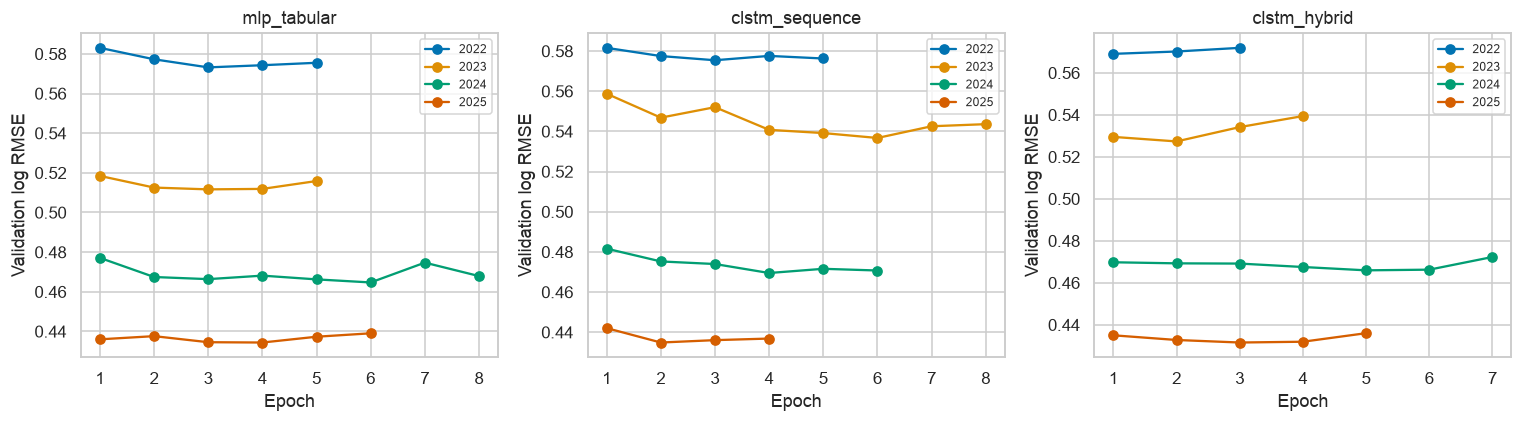

blend_hybrid_lgbm  lgbm_61_ratios_large_tuned  \
dimension   segment                                                           
actual_tail lower_99pct                  0.4523                      0.4538   
            top_1pct                     1.1630                      1.1094   
event       month_end                    0.6403                      0.6479   
            monthly_expiry               0.5406                      0.5402   
            quarterly_expiry             0.7667                      0.7591   
            regular                      0.4432                      0.4431   
size        large                        0.3923                      0.3926   
            mid                          0.4274                      0.4268   
            small                        0.5706                      0.5713   

                              nn_cnn_lstm_hybrid  nn_cnn_lstm_sequence  \
dimension   segment                                                      
actual_tail lower_99pct                   0.4663                0.4743   
            top_1pct                      1.2450                1.2236   
event       month_end                     0.6515                0.6648   
            monthly_expiry                0.5489                0.5436   
            quarterly_expiry              0.8106                0.8477   
            regular                       0.4587                0.4651   
size        large                         0.4044                0.4117   
            mid                           0.4422                0.4480   
            small                         0.5902                0.5987   

                              nn_mlp_tabular  
dimension   segment                           
actual_tail lower_99pct               0.4606  
            top_1pct                  1.0959  
event       month_end                 0.6870  
            monthly_expiry            0.5469  
            quarterly_expiry          0.7706  
            regular                   0.4466  
size        large                     0.3985  
            mid                       0.4332  
            small                     0.5780

In [7]:
training_history=read(N,'training_history.csv')
summary_nn=neural_metrics[neural_metrics.test_year.isin(DEV)].groupby('candidate').agg(
    development_log_RMSE=('rmse_log','mean'),WAPE=('wape','mean'),bias=('aggregate_bias','mean'))
summary_nn['2025_log_RMSE']=annual_neural[2025]
summary_nn['change_vs_tuned']=summary_nn.development_log_RMSE-summary_nn.loc[TUNED,'development_log_RMSE']
display(summary_nn.sort_values('development_log_RMSE'))
display(read(N,'error_correlation.csv').rename(columns={'Unnamed: 0':'model'}).set_index('model'))
fig,axes=plt.subplots(1,3,figsize=(14,4))
for (name,mode),ax in zip(NN_CANDIDATES,axes):
    for year,group in training_history.query("phase == 'tune' and candidate == @name").groupby('test_year'):
        ax.plot(group.epoch,group.validation_rmse_log,marker='o',label=str(year))
    ax.set(title=name.replace('nn_',''),xlabel='Epoch',ylabel='Validation log RMSE')
    ax.legend(fontsize=8)
plt.tight_layout();plt.show()
display(read(N,'segment_rmse.csv').set_index(['dimension','segment']))

The saved MLP, sequence and hybrid development log RMSEs were approximately **0.4700**, **0.4851** and **0.4785**, versus **0.4636** for tuned LightGBM. The hybrid trailed the plain MLP, indicating that adding the sequence branch did not improve this tested architecture. Training loss could keep falling after validation accuracy stopped improving. Calendar-event groups remained difficult.

The fixed blend reached **0.46330** in development and **0.41839** in 2025. Its development improvement of about **0.00027** was below the 0.002 adoption threshold, and two development years worsened. The stronger 2025 result therefore did not determine the selection.

## Worked neural refits and sequence checks

The following example reruns all three architectures for 2022 at the original large row budgets, including historical epoch selection and final refitting. It also refits the tuned LightGBM reference on the same final fitting rows.

For these fresh fits, missing sequence-normalisation references use medians learned on the corresponding historical fitting frame. Alisa's sequence helper computes the fallback medians separately from each scoring dataframe. The fresh example supplies historical values before calling that helper. This affects rows with missing history and is recorded as a reproduction difference. The saved original tables remain unchanged.

In the 2022 evaluation, **327 of 328,634 rows** have a missing auction normalisation reference and **40** have a missing daily-volume reference. This is the scope of the sequence fallback adjustment. Other differences include fresh fitting samples, epoch selection and execution runtime. Those effects have not been isolated from one another.


2026-11-18T06:11:52.903016+00:00 Building the prior-only sequence history store


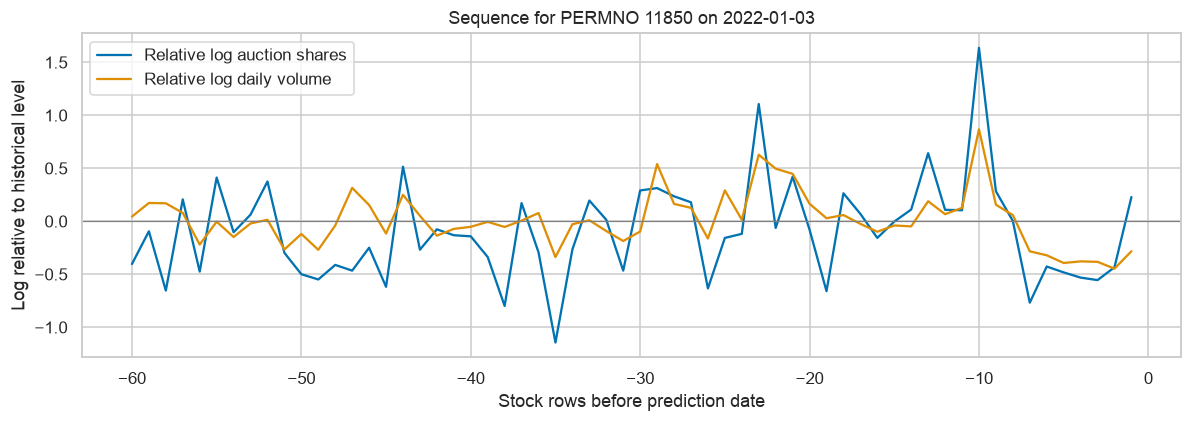

2026-11-18T06:11:54.737253+00:00 Sequence chronology, same-stock membership and finite-input checks passed


In [8]:
progress('Building the prior-only sequence history store')
store=su.build_history_store()
audit=cu.load_period(2022,2023,10000,42)
audit_index=su.sequence_index(store,audit)
windows=su.gather_windows(store,audit_index,np.arange(len(audit)))
present=windows[:,:,-1]==1
positions=audit_index['position'][:,None]-np.arange(su.SEQ_LEN,0,-1)[None,:]
safe=np.clip(positions,0,None)
target_position=audit_index['position'][:,None]
assert (store['date'][safe][present] < np.broadcast_to(store['date'][target_position],safe.shape)[present]).all()
assert (store['permno'][safe][present] == np.broadcast_to(store['permno'][target_position],safe.shape)[present]).all()
assert np.isfinite(windows).all()
example=int(np.argmax(present.all(axis=1)))
fig,ax=plt.subplots(figsize=(11,4))
ax.plot(np.arange(-60,0),windows[example,:,0],label='Relative log auction shares')
ax.plot(np.arange(-60,0),windows[example,:,2],label='Relative log daily volume')
ax.axhline(0,color='grey',linewidth=.8)
ax.set(title=f'Sequence for PERMNO {audit.permno.iloc[example]} on {audit.date.iloc[example]:%Y-%m-%d}',
       xlabel='Stock rows before prediction date',ylabel='Log relative to historical level')
ax.legend();plt.tight_layout();plt.show()
progress('Sequence chronology, same-stock membership and finite-input checks passed')
del windows,audit,audit_index

def training_sequence_index(frame, fitting_frame):
    filled=frame.copy()
    for feature in ['median20_auction_volume','avg20_daily_volume']:
        fallback=float(fitting_frame[feature].median())
        assert np.isfinite(fallback)
        filled[feature]=filled[feature].fillna(fallback)
    return su.sequence_index(store,filled)

def prepare_neural_fold():
    tune=cu.load_period(2016,2021,750000,cu.SEED+2022)
    valid=cu.load_period(2021,2022,150000,cu.SEED+100+2022)
    refit=cu.load_period(2017,2022,1000000,cu.SEED+200+2022)
    test=cu.load_period(2022,2023)
    assert tune.date.max()<valid.date.min() and valid.date.max()<test.date.min() and refit.date.max()<test.date.min()
    for phase,frame in [('tune',tune),('validation',valid),('refit',refit),('test',test)]:
        write_frame(frame[['date','permno']],RUN/f'samples/neural_2022_{phase}_keys.parquet')
    xt,pt=fit_preprocessor(tune,cu.CONTINUOUS,cu.BOOLEAN,cu.CATEGORICAL)
    xv=apply_preprocessor(valid,pt,cu.CONTINUOUS,cu.BOOLEAN,cu.CATEGORICAL)
    xr,pr=fit_preprocessor(refit,cu.CONTINUOUS,cu.BOOLEAN,cu.CATEGORICAL)
    xe=apply_preprocessor(test,pr,cu.CONTINUOUS,cu.BOOLEAN,cu.CATEGORICAL)
    zt,vbase=cu.residual_target_and_base(tune,valid)
    zr,tbase=cu.residual_target_and_base(refit,test)
    write_json(RUN/'models/neural_preprocessing.json',{'plan_hash':PLAN_HASH,'tune':pt,'refit':pr,
        'tune_normalisation_fallbacks':{f:float(tune[f].median()) for f in ['median20_auction_volume','avg20_daily_volume']},
        'refit_normalisation_fallbacks':{f:float(refit[f].median()) for f in ['median20_auction_volume','avg20_daily_volume']},
        'target_fallback':float(refit.auction_volume.median()),'bounds':np.quantile(refit.log1p_auction_volume,[.001,.999]).tolist()})
    data={'xt':xt,'xv':xv,'xr':xr,'xe':xe,'zt':zt,'zr':zr,'pt':pt,'pr':pr,
          'it':training_sequence_index(tune,tune),'iv':training_sequence_index(valid,tune),
          'ir':training_sequence_index(refit,refit),'ie':training_sequence_index(test,refit),
          'tune_log':tune.log1p_auction_volume.to_numpy(float),'refit_log':refit.log1p_auction_volume.to_numpy(float),
          'valid_log':valid.log1p_auction_volume.to_numpy(float),'vbase':vbase,'tbase':tbase,
          'keys':test[['date','permno','auction_volume']].copy()}
    return data

In [9]:
neural_output_path=RUN/'predictions/neural_worked_2022.parquet'
if neural_output_path.is_file() and (RUN/'neural_worked_metrics.csv').is_file():
    neural_output=sql(f"SELECT * FROM read_parquet('{neural_output_path}') ORDER BY date,permno")
    neural_worked=read(RUN,'neural_worked_metrics.csv')
    fresh_history=read(RUN,'neural_worked_history.csv')
    progress('Reusing completed fresh 2022 neural refits')
else:
    progress('Preparing large-tier neural training and validation data')
    data=prepare_neural_fold()
    output=data['keys'].copy();rows=[];histories=[]
    for number,(name,mode) in enumerate(NN_CANDIDATES):
        mt=su.tabular_mask(data['pt'],mode);mr=su.tabular_mask(data['pr'],mode)
        progress(f'2022 {name}: selecting epochs on 2021')
        validation={'x_tab':data['xv'][:,mt],'index':data['iv'],'base':data['vbase'],
                    'y_log':data['valid_log'],'train_log':data['tune_log']}
        model,epochs,history=su.train(mode,data['xt'][:,mt],data['zt'],store,data['it'],
                                     cu.SEED+2022+number,su.TRAIN['max_epochs'],validation,log=progress)
        histories.extend({'candidate':name,'phase':'tune',**entry} for entry in history)
        del model
        gc.collect()
        if su.DEVICE.type=='mps':torch.mps.empty_cache()
        progress(f'2022 {name}: refitting for {epochs} selected epochs')
        model,_,history=su.train(mode,data['xr'][:,mr],data['zr'],store,data['ir'],
                                cu.SEED+300+2022+number,epochs,log=progress)
        histories.extend({'candidate':name,'phase':'refit',**entry} for entry in history)
        component=su.predict(model,data['xe'][:,mr],store,data['ie'])
        output[name]=np.maximum(np.expm1(cu.final_log_prediction(component,data['tbase'],data['refit_log'])),0)
        assert np.isfinite(output[name]).all()
        path=RUN/f'models/{name}_2022.pt'
        torch.save({key:value.detach().cpu() for key,value in model.state_dict().items()},path)
        restored=su.DailyNet(mode,int(mr.sum())).to(su.DEVICE)
        restored.load_state_dict(torch.load(path,map_location=su.DEVICE,weights_only=True))
        short={key:value[:1024] for key,value in data['ie'].items()}
        original_small=su.predict(model,data['xe'][:1024,mr],store,short)
        restored_small=su.predict(restored,data['xe'][:1024,mr],store,short)
        np.testing.assert_allclose(restored_small,original_small,rtol=1e-5,atol=1e-5)
        result={'candidate':name,'epochs':int(epochs),**forecast_metrics(output.auction_volume,output[name])}
        rows.append(result)
        progress(f'2022 {name}: log RMSE={result["rmse_log"]:.6f}')
        del model,restored
        gc.collect()
        if su.DEVICE.type=='mps':torch.mps.empty_cache()
    trials=read(A,'hyperparameter_validation.csv').query('candidate == @TUNED and test_year == 2022')
    choice=trials.loc[trials.validation_rmse_log.idxmin()]
    progress('Refitting the tuned LightGBM reference on the neural final fitting rows')
    model=lgb.LGBMRegressor(n_estimators=max(25,int(choice.best_iteration)),random_state=cu.SEED+300+2022,
                           n_jobs=6,deterministic=True,force_col_wise=True,verbosity=-1,**json.loads(choice['config']))
    model.fit(data['xr'],data['zr'])
    output[TUNED]=np.maximum(np.expm1(cu.final_log_prediction(model.predict(data['xe']),data['tbase'],data['refit_log'])),0)
    model.booster_.save_model(str(RUN/'models/tuned_reference_2022.txt'))
    output['blend_hybrid_lgbm']=np.expm1(.5*np.log1p(output[TUNED])+.5*np.log1p(output.nn_cnn_lstm_hybrid))
    for name in [TUNED,'blend_hybrid_lgbm']:
        rows.append({'candidate':name,'epochs':np.nan,**forecast_metrics(output.auction_volume,output[name])})
    write_frame(output,neural_output_path)
    neural_worked=pd.DataFrame(rows);neural_worked.to_csv(RUN/'neural_worked_metrics.csv',index=False)
    fresh_history=pd.DataFrame(histories);fresh_history.to_csv(RUN/'neural_worked_history.csv',index=False)
    neural_output=output
    del data,model
    gc.collect()
    if su.DEVICE.type=='mps':torch.mps.empty_cache()
published=neural_metrics.query('test_year == 2022').set_index('candidate')
comparison=neural_worked.set_index('candidate')[['rmse_log','wape','aggregate_bias']].join(
    published[['rmse_log','wape']].rename(columns={'rmse_log':'published_2022_log_RMSE','wape':'published_2022_WAPE'}))
comparison.to_csv(RUN/'neural_2022_comparison.csv')
display(comparison)

2026-11-18T06:11:54.758896+00:00 Reusing completed fresh 2022 neural refits


,rmse_log,wape,aggregate_bias,published_2022_log_RMSE,published_2022_WAPE
candidate,,,,,
nn_mlp_tabular,0.5077,0.3642,-0.1624,0.5050,0.3661
nn_cnn_lstm_sequence,0.5376,0.3835,-0.1404,0.5417,0.3940
nn_cnn_lstm_hybrid,0.5307,0.3785,-0.1165,0.5253,0.3736
lgbm_61_ratios_large_tuned,0.5046,0.3597,-0.1621,0.5025,0.3598
blend_hybrid_lgbm,0.5051,0.3617,-0.1467,0.5036,0.3615


## Why a blend can help even when the network is weaker

Let $e_L$ and $e_N$ be log errors for LightGBM and the network. For a fixed equal-weight log blend,

$$\mathrm{MSE}_{blend}=\tfrac14\mathrm{MSE}_L+\tfrac14\mathrm{MSE}_N+\tfrac12 E[e_L e_N].$$

The cross-moment determines how much the models' errors reinforce each other. The normalized cross-moment $E[e_Le_N]/(\mathrm{RMSE}_L\mathrm{RMSE}_N)$ is an uncentred error similarity. It differs from Pearson correlation when mean errors are nonzero. Diversification can lower error if the two models are accurate enough and their errors do not overlap too much.

Alisa's fixed blend helped more in 2024 and 2025, when the hybrid was closer to LightGBM in standalone accuracy. The following cell verifies the identity exactly on the fresh 2022 predictions and records whether that year's blend gains.

,fresh 2022 blend decomposition
LightGBM_RMSE,0.5046
hybrid_RMSE,0.5307
blend_RMSE,0.5051
Pearson_error_correlation,0.9070
uncentred_error_similarity,0.9039
break_even_similarity,0.9005


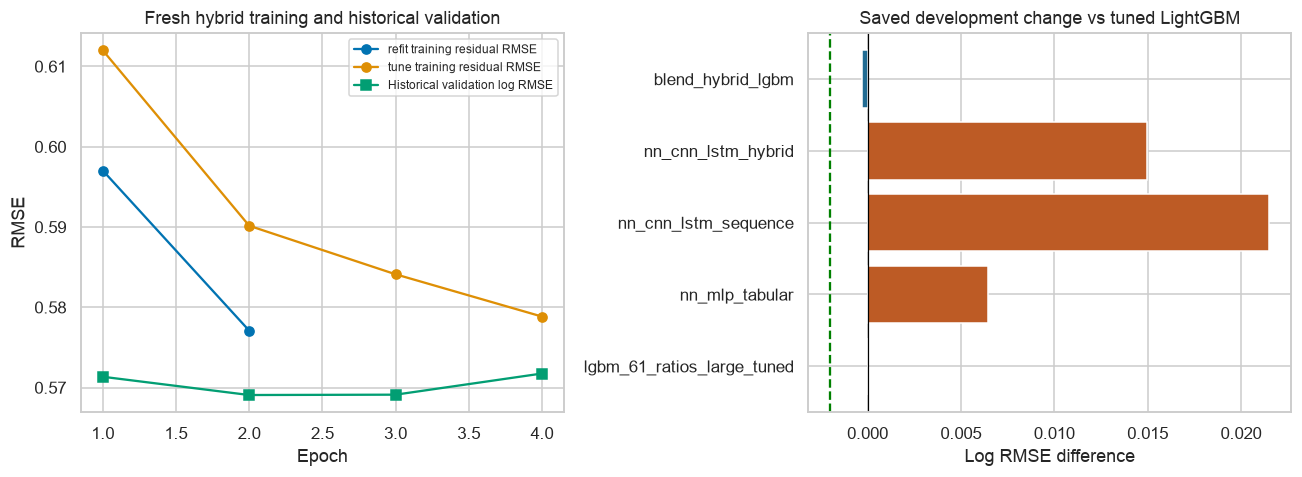

In [10]:
y=np.log1p(neural_output.auction_volume.to_numpy(float))
e_l=np.log1p(neural_output[TUNED].to_numpy(float))-y
e_n=np.log1p(neural_output.nn_cnn_lstm_hybrid.to_numpy(float))-y
e_b=np.log1p(neural_output.blend_hybrid_lgbm.to_numpy(float))-y
identity=.25*np.mean(e_l**2)+.25*np.mean(e_n**2)+.5*np.mean(e_l*e_n)
np.testing.assert_allclose(np.mean(e_b**2),identity,rtol=1e-12,atol=1e-12)
sigma_l=np.sqrt(np.mean(e_l**2));sigma_n=np.sqrt(np.mean(e_n**2))
diversification={'LightGBM_RMSE':sigma_l,'hybrid_RMSE':sigma_n,'blend_RMSE':np.sqrt(identity),
                 'Pearson_error_correlation':np.corrcoef(e_l,e_n)[0,1],
                 'uncentred_error_similarity':np.mean(e_l*e_n)/(sigma_l*sigma_n),
                 'break_even_similarity':(3*sigma_l**2-sigma_n**2)/(2*sigma_l*sigma_n)}
display(pd.Series(diversification,name='fresh 2022 blend decomposition').to_frame())
write_json(RUN/'blend_decomposition_2022.json',{key:float(value) for key,value in diversification.items()})
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for phase,group in fresh_history.query("candidate == 'nn_cnn_lstm_hybrid'").groupby('phase'):
    axes[0].plot(group.epoch,np.sqrt(group.train_mse),marker='o',label=f'{phase} training residual RMSE')
    if group.validation_rmse_log.notna().any():axes[0].plot(group.epoch,group.validation_rmse_log,marker='s',label='Historical validation log RMSE')
axes[0].set(title='Fresh hybrid training and historical validation',xlabel='Epoch',ylabel='RMSE')
axes[0].legend(fontsize=8)
part=summary_nn.loc[[TUNED,'nn_mlp_tabular','nn_cnn_lstm_sequence','nn_cnn_lstm_hybrid','blend_hybrid_lgbm']]
axes[1].barh(part.index,part.change_vs_tuned,color=['#216c93' if value<=0 else '#bd5b25' for value in part.change_vs_tuned])
axes[1].axvline(-.002,color='green',linestyle='--');axes[1].axvline(0,color='black',linewidth=.8)
axes[1].set(title='Saved development change vs tuned LightGBM',xlabel='Log RMSE difference')
plt.tight_layout();plt.show()

## Decisions and limits

The **complete saved HMM study** retains the untuned large-tier tree control over each regime augmentation. The **complete saved neural study** retains tuned LightGBM over the MLP, sequence, hybrid and fixed blend under its adoption rule. The fixed blend has a slightly lower development point estimate, but its gain is too small and its earlier-year results are uneven.

The fresh 2022 tables above may differ numerically. They reuse the recipes and historical information windows while recording execution versions, newly fitted HMMs and samples, and training-only sequence fallback values. The worked examples assess one year, so the saved full development decisions and the fresh examples have different evidential scopes.

The original bootstrap files use independently resampled whole dates. They measure daily log-MAE differences, preserve within-date cross-sectional dependence, and omit adjacent-date dependence, model refitting and repeated research-selection uncertainty. Several explored architectures share the same inspected years. The 2025 results remain retrospective confirmation.

Regime persistence, error diversification and subgroup diagnostics remain useful explanations of the experiments. None of these saved studies established a qualifying replacement for the tuned daily LightGBM.

## Source map

| Part | Sources relative to repository root |
| --- | --- |
| Regime motivation and input diagnostics | `outputs/eda/16c_regime_motivation`, `notebooks/16c_regime_motivation.ipynb` |
| Historical HMM features and tree comparison | `outputs/eda/16d_hmm_regime_features`, `notebooks/16d_hmm_regime_features.ipynb` |
| Neural models and blend | `outputs/eda/16e_sequence_neural_networks`, `notebooks/16e_sequence_neural_networks.ipynb` |
| Implementations | `notebooks/regime_utils.py`, `notebooks/sequence_utils.py`, `notebooks/challenger_utils.py` |
| Fresh worked models, inputs and predictions | `outputs/experiments/29_regimes_neural_master_audit` |

Checkpoint 5 remains pending. The next notebook is **08 — Splines, tail mixtures, Tweedie loss and rebalance features**.

In the fresh 2022 example, tuned LightGBM scored **0.50461**, the MLP **0.50774**, the sequence network **0.53757**, the hybrid **0.53066** and the fixed blend **0.50505** in log RMSE. All regime additions also trailed their freshly fitted HMM control in that year. These worked results agree with the broad preference for the tree forecast. They are a single-year implementation check alongside the saved multi-year evidence.


In [11]:
# Verify fresh complete evaluation keys and independently recompute their metrics.
reference_path=RESULTS/'eda/09_global_finalists/predictions/global_finalist_predictions_2022.parquet'
reference=sql(f"SELECT date,permno,auction_volume FROM read_parquet('{reference_path}') ORDER BY date,permno")
for filename,metrics_frame in [('hmm_worked_2022.parquet',hmm_worked),('neural_worked_2022.parquet',neural_worked)]:
    path=RUN/'predictions'/filename
    predictions=sql(f"SELECT * FROM read_parquet('{path}') ORDER BY date,permno")
    assert not predictions.duplicated(['date','permno']).any()
    np.testing.assert_array_equal(predictions[['date','permno','auction_volume']],reference)
    for row in metrics_frame.itertuples():
        name=row.candidate
        actual=forecast_metrics(predictions.auction_volume,predictions[name])
        for metric in ['observations','rmse_log','wape','aggregate_bias']:
            np.testing.assert_allclose(actual[metric],getattr(row,metric),rtol=1e-10,atol=1e-10)
        independent=sql(f"SELECT sqrt(avg(pow(ln(1+{name})-ln(1+auction_volume),2))) AS rmse_log, sum(abs({name}-auction_volume))/sum(auction_volume) AS wape FROM read_parquet('{path}')").iloc[0]
        np.testing.assert_allclose(independent,[row.rmse_log,row.wape],rtol=1e-10,atol=1e-10)
# Reconstruct the tuned reference from its saved preprocessing and tree model.
settings=json.loads((RUN/'models/neural_preprocessing.json').read_text())
prep=settings['refit']
types=tuple(list(prep[key]) for key in ['continuous','boolean','categorical'])
frame=cu.load_period(2022,2023).head(2048)
x=apply_preprocessor(frame,prep,*types)
restored=lgb.Booster(model_file=str(RUN/'models/tuned_reference_2022.txt'))
base=np.log1p(frame.median20_auction_volume.fillna(settings['target_fallback']).to_numpy(float))
forecast=np.maximum(np.expm1(np.clip(base+restored.predict(x,num_threads=6),*settings['bounds'])),0)
reference_predictions=neural_output.sort_values(['date','permno']).iloc[:len(frame)]
np.testing.assert_array_equal(frame[['date','permno']],reference_predictions[['date','permno']])
np.testing.assert_allclose(forecast,reference_predictions[TUNED],rtol=1e-12,atol=1e-9)

source_checks=pd.DataFrame(source_check_rows)
source_checks.to_csv(RUN/'source_summary_checks.csv',index=False)
write_json(RUN/'verification_summary.json',{'status':'passed','plan_hash':PLAN_HASH,
           'source_comparisons':len(source_checks),'fresh_model_score_comparisons':len(hmm_worked)+len(neural_worked),
           'fresh_evaluation_rows':len(reference),'forward_filter_no_lookahead':True,'sequence_history_prior_only':True,
           'training_only_sequence_fallbacks':True,'independent_sql_metrics':True,'blend_identity':True})
progress('Notebook 07 complete: source decisions, fresh worked fits, sequence/filter timing, reloads and metric checks passed.')
cu.con.close();con.close();work.cleanup()

2026-11-18T06:11:57.064299+00:00 Notebook 07 complete: source decisions, fresh worked fits, sequence/filter timing, reloads and metric checks passed.
